# Accel BizFlow - Phase 0 Business Analysis

This notebook is the reproducible Phase 0 analysis for the case competition. All records are synthetic competition data. Run the cells from top to bottom.

The notebook validates the supplied files, reproduces the locked roadmap metrics, and records evidence needed before implementation. Scenario projections are assumptions, not observed prototype results.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid")

# Works when launched from the project root, the analysis folder, or VS Code.
PROJECT_ROOT = Path.cwd()
for candidate in (PROJECT_ROOT, PROJECT_ROOT.parent):
    if (candidate / "YTL_TrackA_Udyam_Digital_Data").is_dir():
        PROJECT_ROOT = candidate
        break
else:
    PROJECT_ROOT = Path(r"C:\Users\ACER\Downloads\AirtelSync")

DATA_DIR = PROJECT_ROOT / "YTL_TrackA_Udyam_Digital_Data"
assert DATA_DIR.is_dir(), f"Data directory not found: {DATA_DIR}"
print(f"Using data directory: {DATA_DIR}")


Using data directory: c:\Users\ACER\Downloads\AirtelSync\YTL_TrackA_Udyam_Digital_Data


In [2]:
date_columns = [
    "created_date",
    "contacted_date",
    "needs_assessed_date",
    "quote_accepted_date",
    "kyc_complete_date",
    "activated_date",
]

leads = pd.read_csv(DATA_DIR / "smb_leads.csv", parse_dates=date_columns)
products = pd.read_csv(DATA_DIR / "product_catalogue.csv")
gstin = pd.read_csv(DATA_DIR / "mock_gstin_registry.csv")
udyam = pd.read_csv(DATA_DIR / "mock_udyam_registry.csv")

expected_rows = {"leads": 5000, "products": 25, "gstin": 3534, "udyam": 2723}
actual_rows = {
    "leads": len(leads),
    "products": len(products),
    "gstin": len(gstin),
    "udyam": len(udyam),
}
assert actual_rows == expected_rows, actual_rows
assert leads["lead_id"].is_unique
assert products["product_id"].is_unique
assert gstin["gstin"].is_unique
assert udyam["udyam_number"].is_unique

required_lead_columns = {
    "lead_id", "lead_source", "segment", "stage_reached", "outcome",
    "drop_reason", "employee_count", "num_sites",
    "monthly_bundle_value_inr", "acquisition_cost_inr",
}
required_product_columns = {
    "product_id", "price_min_inr_per_month", "price_max_inr_per_month",
    "one_time_setup_inr", "requires_one_of", "target_segments",
}
assert required_lead_columns.issubset(leads.columns)
assert required_product_columns.issubset(products.columns)

print(actual_rows)


{'leads': 5000, 'products': 25, 'gstin': 3534, 'udyam': 2723}


## Funnel reconciliation

Stage counts are derived from non-null stage dates rather than copied from the case narrative.


In [3]:
stage_columns = {
    "Leads generated": "created_date",
    "Contacted": "contacted_date",
    "Needs assessed": "needs_assessed_date",
    "Quote accepted": "quote_accepted_date",
    "KYC complete": "kyc_complete_date",
    "Activated": "activated_date",
}

funnel = pd.DataFrame({"stage": list(stage_columns)})
funnel["count"] = [leads[column].notna().sum() for column in stage_columns.values()]
funnel["conversion_from_previous_pct"] = (
    funnel["count"].div(funnel["count"].shift(1)).mul(100)
)
funnel.loc[0, "conversion_from_previous_pct"] = np.nan
display(funnel)
assert funnel["count"].tolist() == [5000, 3406, 1974, 861, 588, 368]

activated = leads.loc[leads["outcome"].eq("Activated")].copy()
total_acquisition_spend = leads["acquisition_cost_inr"].sum()
baseline_cac = total_acquisition_spend / len(activated)
print(f"Total acquisition spend: INR {total_acquisition_spend:,.0f}")
print(f"Baseline CAC: INR {baseline_cac:,.0f}")
print(f"Lead-to-activation: {len(activated) / len(leads):.2%}")


,stage,count,conversion_from_previous_pct
0,Leads generated,5000,NaN
1,Contacted,3406,68.12
2,Needs assessed,1974,57.96
3,Quote accepted,861,43.62
4,KYC complete,588,68.29
5,Activated,368,62.59


Total acquisition spend: INR 5,539,640
Baseline CAC: INR 15,053
Lead-to-activation: 7.36%


## Segment and acquisition-source economics

Confidence intervals are Wilson 95% intervals for descriptive comparison.


In [4]:
def wilson_interval(successes, trials, z=1.96):
    proportion = successes / trials
    denominator = 1 + z**2 / trials
    centre = proportion + z**2 / (2 * trials)
    spread = z * np.sqrt((proportion * (1 - proportion) + z**2 / (4 * trials)) / trials)
    return (centre - spread) / denominator, (centre + spread) / denominator

segment_analysis = leads.groupby("segment").agg(
    leads=("lead_id", "size"),
    activated=("outcome", lambda values: values.eq("Activated").sum()),
    acquisition_spend=("acquisition_cost_inr", "sum"),
)
segment_analysis["conversion"] = segment_analysis["activated"] / segment_analysis["leads"]
segment_analysis["cac"] = segment_analysis["acquisition_spend"] / segment_analysis["activated"]
segment_analysis["monthly_value_proxy"] = activated.groupby("segment")["monthly_bundle_value_inr"].sum()
segment_analysis["value_share"] = segment_analysis["monthly_value_proxy"] / segment_analysis["monthly_value_proxy"].sum()
segment_analysis[["conversion_ci_low", "conversion_ci_high"]] = [
    wilson_interval(row.activated, row.leads)
    for row in segment_analysis.itertuples()
]
display(segment_analysis.sort_values("conversion", ascending=False))

source_analysis = leads.groupby("lead_source").agg(
    leads=("lead_id", "size"),
    activated=("outcome", lambda values: values.eq("Activated").sum()),
    acquisition_spend=("acquisition_cost_inr", "sum"),
)
source_analysis["conversion"] = source_analysis["activated"] / source_analysis["leads"]
source_analysis["cac"] = source_analysis["acquisition_spend"] / source_analysis["activated"]
display(source_analysis.sort_values("conversion", ascending=False))


,leads,activated,acquisition_spend,conversion,cac,monthly_value_proxy,value_share,conversion_ci_low,conversion_ci_high
segment,,,,,,,,,
Small manufacturers,289,37,567000,0.13,"15,324.32","739,250.00",0.16,0.09,0.17
Professional offices,1247,138,1475870,0.11,"10,694.71","937,830.00",0.21,0.09,0.13
Small multi-site businesses,755,83,1295990,0.11,"15,614.34","2,592,380.00",0.57,0.09,0.13
Micro retail & services,2709,110,2200780,0.04,"20,007.09","275,530.00",0.06,0.03,0.05


,leads,activated,acquisition_spend,conversion,cac
lead_source,,,,,
Referral,413,61,250020,0.15,"4,098.69"
Inbound call,504,48,245440,0.10,"5,113.33"
Channel partner,1010,81,1688930,0.08,"20,850.99"
Field sales,1720,125,3041870,0.07,"24,334.96"
Website form,995,43,273120,0.04,"6,351.63"
WhatsApp campaign,358,10,40260,0.03,"4,026.00"


## Funnel loss reasons

Quote-stage losses are classified into mutually exclusive groups: price/competitor, quote complexity/delay, and waiting.


,stage_reached,drop_reason,losses
9,Lead,Unreachable after 3 attempts,805
2,Contacted,Owner had no time for a visit,531
8,Lead,Not interested on first call,470
13,Needs assessed,Price too high,414
0,Contacted,Locked in with current provider,325
10,Lead,Wrong or invalid number,319
3,Contacted,Visit not scheduled by sales,296
1,Contacted,Only wanted a mobile plan,280
11,Needs assessed,Competitor offered cheaper plan,207
14,Needs assessed,Quote too complex to understand,206


,value
price_or_competitor_losses,621.00
complexity_or_delay_losses,385.00
waiting_losses,107.00
all_assessment_losses,"1,113.00"
price_or_competitor_share,0.56
complexity_or_delay_share,0.35
waiting_share,0.10


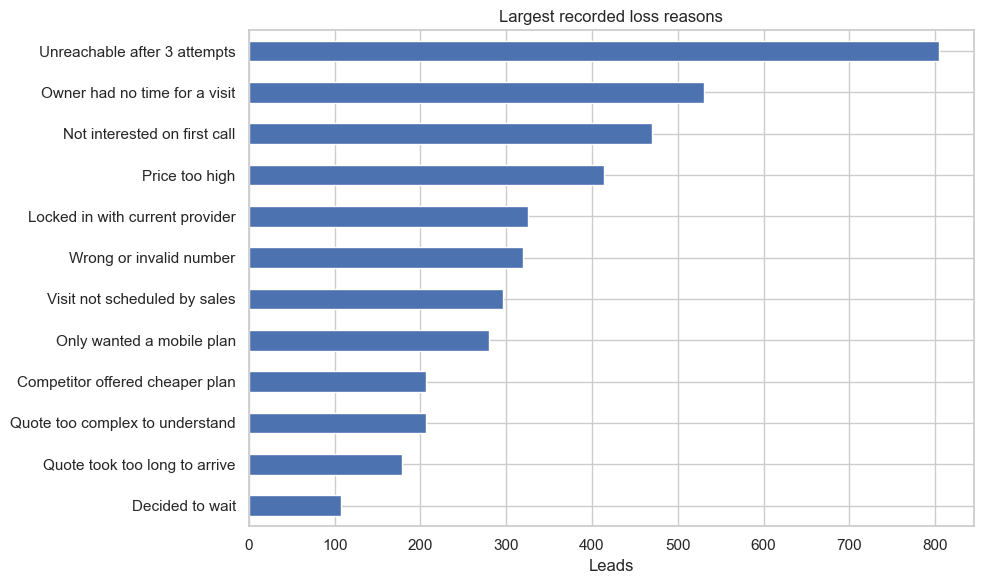

In [5]:
drop_reason_analysis = (
    leads.loc[leads["outcome"].eq("Dropped")]
    .groupby(["stage_reached", "drop_reason"], dropna=False)
    .size()
    .reset_index(name="losses")
    .sort_values("losses", ascending=False)
)
display(drop_reason_analysis)

quote_losses = drop_reason_analysis.loc[
    drop_reason_analysis["stage_reached"].eq("Needs assessed")
].copy()
price_reasons = {"Price too high", "Competitor offered cheaper plan"}
complexity_reasons = {"Quote too complex to understand", "Quote took too long to arrive"}
waiting_reasons = {"Decided to wait"}
quote_summary = pd.Series({
    "price_or_competitor_losses": quote_losses.loc[quote_losses["drop_reason"].isin(price_reasons), "losses"].sum(),
    "complexity_or_delay_losses": quote_losses.loc[quote_losses["drop_reason"].isin(complexity_reasons), "losses"].sum(),
    "waiting_losses": quote_losses.loc[quote_losses["drop_reason"].isin(waiting_reasons), "losses"].sum(),
    "all_assessment_losses": quote_losses["losses"].sum(),
}, dtype="float64")
quote_summary["price_or_competitor_share"] = quote_summary["price_or_competitor_losses"] / quote_summary["all_assessment_losses"]
quote_summary["complexity_or_delay_share"] = quote_summary["complexity_or_delay_losses"] / quote_summary["all_assessment_losses"]
quote_summary["waiting_share"] = quote_summary["waiting_losses"] / quote_summary["all_assessment_losses"]
display(quote_summary.to_frame("value"))
assert quote_summary["price_or_competitor_losses"] == 621
assert quote_summary["complexity_or_delay_losses"] == 385
assert quote_summary["waiting_losses"] == 107
assert quote_summary["all_assessment_losses"] == 1113

plot_data = drop_reason_analysis.head(12).sort_values("losses")
plot_data.plot.barh(
    x="drop_reason", y="losses", legend=False, figsize=(10, 6),
    title="Largest recorded loss reasons",
)
plt.xlabel("Leads")
plt.ylabel("")
plt.tight_layout()
plt.show()


## Activated-customer outcomes and bundle diversity

Activated bundle patterns are descriptive evidence only; they must not become hardcoded universal bundles.


In [6]:
activated["bundle_key"] = activated["bundle_products"].fillna("").str.replace(";", "|", regex=False)
bundle_frequency = (
    activated["bundle_key"]
    .value_counts()
    .rename_axis("bundle")
    .reset_index(name="activated_customers")
)
display(bundle_frequency.head(15))
print(f"Unique activated bundle configurations: {bundle_frequency.shape[0]}")

outcome_summary = pd.Series({
    "activated_customers": len(activated),
    "churned_within_6_months": activated["churned_within_6_months"].eq("Y").sum(),
    "churn_rate": activated["churned_within_6_months"].eq("Y").mean(),
    "median_monthly_bundle_value_inr": activated["monthly_bundle_value_inr"].median(),
    "mean_days_to_activation": activated["days_lead_to_activation"].mean(),
    "median_days_to_activation": activated["days_lead_to_activation"].median(),
    "mean_follow_up_calls": activated["customer_follow_up_calls"].mean(),
    "median_nps": activated["nps_score"].median(),
})
display(outcome_summary.to_frame("value"))


,bundle,activated_customers
0,P01x1|P07x1,11
1,P01x1|P07x2,10
2,P01x1|P07x2|P19x1,6
3,P01x1|P07x2|P23x2,5
4,P01x1|P07x1|P22x1,4
5,P01x1|P07x1|P19x1,4
6,P01x1|P07x2|P19x1|P22x1,4
7,P01x1|P07x2|P22x1,4
8,P01x1|P07x2|P22x1|P23x2,3
9,P01x1|P07x1|P15x1,3


Unique activated bundle configurations: 306


,value
activated_customers,368.00
churned_within_6_months,56.00
churn_rate,0.15
median_monthly_bundle_value_inr,"6,900.00"
mean_days_to_activation,17.62
median_days_to_activation,17.00
mean_follow_up_calls,3.01
median_nps,7.00


## Pilot feasibility and corrected CAC scenarios

City-level assessed-lead volume informs pilot geography. The platform cost is included only in BizFlow scenarios, making the comparison like-for-like.


,,assessed_leads,quote_accepted,activated,quote_acceptance,activation_rate_from_assessed
city,city_tier,,,,,
Delhi,1,187,83,45,0.44,0.24
Mumbai,1,163,74,36,0.45,0.22
Bengaluru,1,158,67,33,0.42,0.21
Hyderabad,1,131,63,25,0.48,0.19
Chennai,1,110,46,21,0.42,0.19
Kolkata,1,96,44,21,0.46,0.22
Pune,1,89,36,22,0.40,0.25
Ahmedabad,1,85,38,18,0.45,0.21
Vadodara,2,81,33,8,0.41,0.10


Assessed leads in professional + multi-site segments: 837


,scenario,activations,platform_cost,acquisition_plus_platform_spend,cac
0,Current process,368,0,5539640,"15,053.37"
1,BizFlow base,588,1000000,6539640,"11,121.84"
2,BizFlow upside,705,1000000,6539640,"9,276.09"


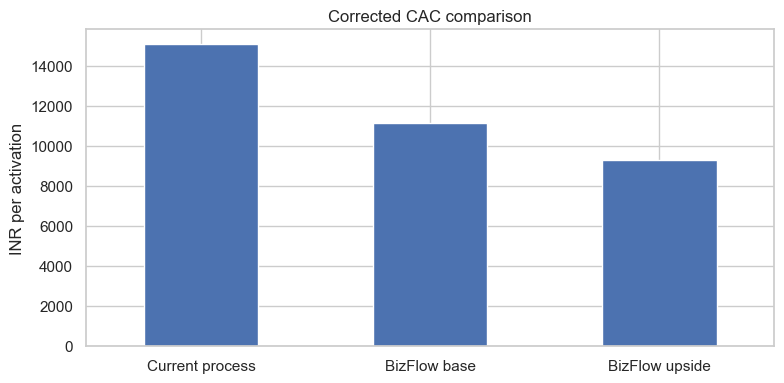

In [7]:
assessed = leads.loc[leads["needs_assessed_date"].notna()].copy()
city_volume = (
    assessed.groupby(["city", "city_tier"])
    .agg(
        assessed_leads=("lead_id", "size"),
        quote_accepted=("quote_accepted_date", "count"),
        activated=("activated_date", "count"),
    )
    .sort_values("assessed_leads", ascending=False)
)
city_volume["quote_acceptance"] = city_volume["quote_accepted"] / city_volume["assessed_leads"]
city_volume["activation_rate_from_assessed"] = city_volume["activated"] / city_volume["assessed_leads"]
display(city_volume.head(20))

priority_segments = {"Professional offices", "Small multi-site businesses"}
priority_assessed = assessed["segment"].isin(priority_segments).sum()
print(f"Assessed leads in professional + multi-site segments: {priority_assessed}")

platform_cost = 1_000_000
scenario = pd.DataFrame({
    "scenario": ["Current process", "BizFlow base", "BizFlow upside"],
    "activations": [368, 588, 705],
    "platform_cost": [0, platform_cost, platform_cost],
})
scenario["acquisition_plus_platform_spend"] = total_acquisition_spend + scenario["platform_cost"]
scenario["cac"] = scenario["acquisition_plus_platform_spend"] / scenario["activations"]
display(scenario)

scenario.plot.bar(
    x="scenario", y="cac", legend=False, figsize=(8, 4),
    title="Corrected CAC comparison",
)
plt.ylabel("INR per activation")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Phase 0 findings

- Quote-stage losses require both price-fit/packaging work and faster, clearer quotes; an advisor alone is insufficient.
- Professional offices are the digital-first priority; multi-site businesses are the high-value assisted priority.
- Catalogue eligibility, dependencies, and pricing must be deterministic and tested before connecting an LLM.
- City-level assessed-lead volume must determine pilot geography and duration.
- The current/base/upside CAC comparison includes platform cost only for BizFlow scenarios.
- Bundle analysis is descriptive and must not hardcode a universal bundle.
- This notebook is for business analysis only. Implementation begins after its validation cells pass.
